In [2]:
import numpy as np

ell = 2
m = 2

I_2 = np.eye(2, dtype=int)
S_2 = np.array([[0, 1], [1, 0]], dtype=int)

x = np.kron(S_2, I_2)
y = np.kron(I_2, S_2)

def mpow(M, a):
    return np.linalg.matrix_power(M, a) % 2

A = (mpow(x, 3) + mpow(y, 1) + mpow(y, 2)) % 2
B = (mpow(y, 3) + mpow(x, 1) + mpow(x, 2)) % 2

H_X = np.hstack((A, B)) % 2
H_Z = np.hstack((B.T, A.T)) % 2

print("A:\n", A)
print("B:\n", B)
print("H_X:\n", H_X)
print("H_Z:\n", H_Z)
print("Row weights of H_Z:", H_Z.sum(axis=1))

A:
 [[1 1 1 0]
 [1 1 0 1]
 [1 0 1 1]
 [0 1 1 1]]
B:
 [[1 1 1 0]
 [1 1 0 1]
 [1 0 1 1]
 [0 1 1 1]]
H_X:
 [[1 1 1 0 1 1 1 0]
 [1 1 0 1 1 1 0 1]
 [1 0 1 1 1 0 1 1]
 [0 1 1 1 0 1 1 1]]
H_Z:
 [[1 1 1 0 1 1 1 0]
 [1 1 0 1 1 1 0 1]
 [1 0 1 1 1 0 1 1]
 [0 1 1 1 0 1 1 1]]
Row weights of H_Z: [6 6 6 6]


In [4]:
def gf2_rank(M):
    M = np.array(M, dtype=np.uint8).copy() % 2
    rows, cols = M.shape
    r = 0

    for c in range(cols):
        pivot = None
        for i in range(r, rows):
            if M[i, c]:
                pivot = i
                break

        if pivot is None:
            continue

        if pivot != r:
            M[[r, pivot]] = M[[pivot, r]]

        for i in range(rows):
            if i != r and M[i, c]:
                M[i] ^= M[r]

        r += 1

    return r

rank_HX = gf2_rank(H_X)
rank_HZ = gf2_rank(H_Z)

n = H_X.shape[1]
k = n - rank_HX - rank_HZ

print("n =", n)
print("rank_HX =", rank_HX)
print("rank_HZ =", rank_HZ)
print("k =", k)
print("Commutation check:\n", (H_X @ H_Z.T) % 2)

n = 8
rank_HX = 4
rank_HZ = 4
k = 0
Commutation check:
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]


('v0', 'c0')
('v0', 'c1')
('v0', 'c2')
('v1', 'c0')
('v1', 'c1')
('v1', 'c3')
('v2', 'c0')
('v2', 'c2')
('v2', 'c3')
('v3', 'c1')
('v3', 'c2')
('v3', 'c3')
('v4', 'c0')
('v4', 'c1')
('v4', 'c2')
('v5', 'c0')
('v5', 'c1')
('v5', 'c3')
('v6', 'c0')
('v6', 'c2')
('v6', 'c3')
('v7', 'c1')
('v7', 'c2')
('v7', 'c3')

Clique graph edges:
('v0', 'v1', {'check': 'c1'})
('v0', 'v2', {'check': 'c2'})
('v0', 'v4', {'check': 'c2'})
('v0', 'v5', {'check': 'c1'})
('v0', 'v6', {'check': 'c2'})
('v0', 'v3', {'check': 'c2'})
('v0', 'v7', {'check': 'c2'})
('v1', 'v2', {'check': 'c3'})
('v1', 'v4', {'check': 'c1'})
('v1', 'v5', {'check': 'c3'})
('v1', 'v6', {'check': 'c3'})
('v1', 'v3', {'check': 'c3'})
('v1', 'v7', {'check': 'c3'})
('v2', 'v4', {'check': 'c2'})
('v2', 'v5', {'check': 'c3'})
('v2', 'v6', {'check': 'c3'})
('v2', 'v3', {'check': 'c3'})
('v2', 'v7', {'check': 'c3'})
('v3', 'v4', {'check': 'c2'})
('v3', 'v5', {'check': 'c3'})
('v3', 'v7', {'check': 'c3'})
('v3', 'v6', {'check': 'c3'})
('v4', 

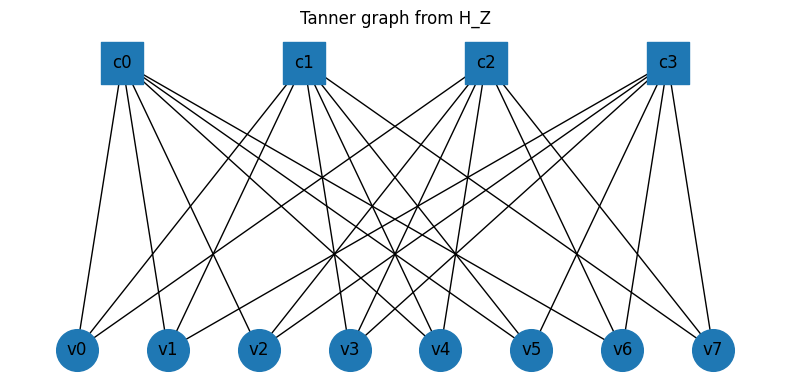

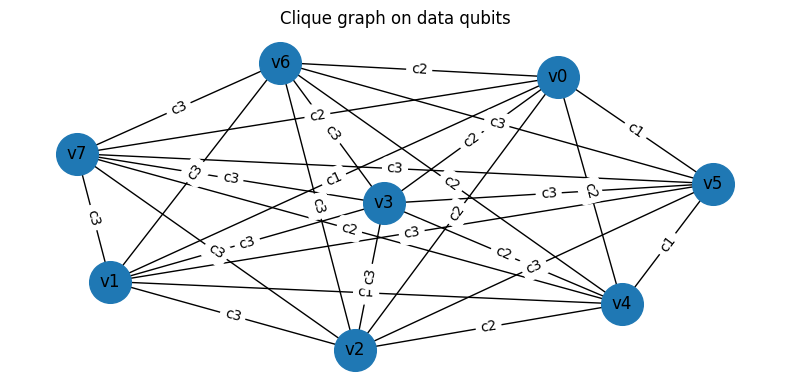

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

n_checks, n_data = H_Z.shape

# ------------------------------------------------------------
# 1. Tanner graph
# ------------------------------------------------------------
GT = nx.Graph()

# Add data qubit nodes
for q in range(n_data):
    GT.add_node(f"v{q}", node_type="data")

# Add Z-check / ancilla nodes
for a in range(n_checks):
    GT.add_node(f"c{a}", node_type="Z_check")

# Add Tanner edges: data qubit d_q is connected to check z_a if H_Z[a, q] = 1
for a in range(n_checks):
    for q in range(n_data):
        if H_Z[a, q] == 1:
            GT.add_edge(f"c{a}", f"v{q}")

# ------------------------------------------------------------
# 2. Clique graph on data qubits
# ------------------------------------------------------------
GC = nx.Graph()

# Add only data qubit nodes
for q in range(n_data):
    GC.add_node(f"v{q}")

# For each check, connect all data qubits touched by that check
for a in range(n_checks):
    data_qubits_in_check = np.where(H_Z[a] == 1)[0]

    for q1, q2 in combinations(data_qubits_in_check, 2):
        GC.add_edge(f"v{q1}", f"v{q2}", check=f"c{a}")

# ------------------------------------------------------------
# Print edges
# ------------------------------------------------------------
for edge in GT.edges():
    print(edge)

print("\nClique graph edges:")
for edge in GC.edges(data=True):
    print(edge)

# ------------------------------------------------------------
# Draw Tanner graph
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

# Put checks on top and data qubits on bottom
pos_tanner = {}

for q in range(n_data):
    pos_tanner[f"v{q}"] = (q, 0)

for a in range(n_checks):
    pos_tanner[f"c{a}"] = (2 * a + 0.5, 1)

data_nodes = [node for node, attr in GT.nodes(data=True) if attr["node_type"] == "data"]
check_nodes = [node for node, attr in GT.nodes(data=True) if attr["node_type"] == "Z_check"]

nx.draw_networkx_nodes(GT, pos_tanner, nodelist=data_nodes, node_shape="o", node_size=900)
nx.draw_networkx_nodes(GT, pos_tanner, nodelist=check_nodes, node_shape="s", node_size=900)
nx.draw_networkx_edges(GT, pos_tanner)
nx.draw_networkx_labels(GT, pos_tanner)

plt.title("Tanner graph from H_Z")
plt.axis("off")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Draw clique graph
# ------------------------------------------------------------
plt.figure(figsize=(8, 4))

pos_clique = nx.spring_layout(GC, seed=1)

nx.draw_networkx_nodes(GC, pos_clique, node_shape="o", node_size=900)
nx.draw_networkx_edges(GC, pos_clique)
nx.draw_networkx_labels(GC, pos_clique)

edge_labels = nx.get_edge_attributes(GC, "check")
nx.draw_networkx_edge_labels(GC, pos_clique, edge_labels=edge_labels)

plt.title("Clique graph on data qubits")
plt.axis("off")
plt.tight_layout()
plt.show()

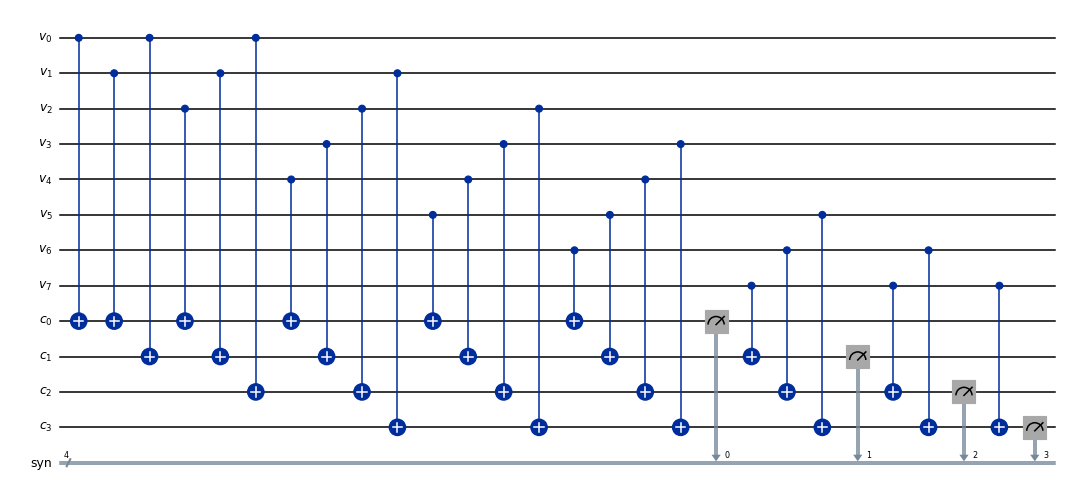

In [12]:

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister


n_checks, n_data = H_Z.shape

data = QuantumRegister(n_data, "v")
anc = QuantumRegister(n_checks, "c")
syn = ClassicalRegister(n_checks, "syn")

qc = QuantumCircuit(data, anc, syn)

for a in range(n_checks):
    for q in range(n_data):
        if H_Z[a, q] == 1:
            qc.cx(data[q], anc[a])
    qc.measure(anc[a], syn[a])

fig = qc.draw(
    output="mpl",
    fold=-1,                 # no wrapping to next row
    scale=0.55,              # make whole drawing smaller
    idle_wires=True,
    cregbundle=True,
    vertical_compression="high"
)

display(fig)